In [1]:
import numpy as np
import tensorflow as tf
import time
from tensorflow.keras import layers, Model

tf.random.set_seed(0)
np.random.seed(0)

In [2]:
class ToyGame:
    """Config + vectorized toy matrix game in one object. B parallel episodes."""

    # --- config (class-level defaults, override via constructor if needed) ---
    N: int = 2
    n_actions: int = 2
    n_states: int = 2
    ep_len: int = 100
    gamma: float = 0.99
    gae_lambda: float = 0.95
    p_no_adv: float = 0.5
    ppo_clip: float = 0.05
    ppo_epochs: int = 5

    def __init__(self, B):
        self.B = B
        self.reset()

    def reset(self):
        self.t = 0
        self.state = np.random.randint(self.n_states, size=self.B)   # (B,) ints
        return self._obs()

    def _obs(self):
        oh = np.zeros((self.B, self.n_states), dtype=np.float32)
        oh[np.arange(self.B), self.state] = 1.0
        return np.repeat(oh[:, None, :], self.N, axis=1)             # (B, N, n_states)

    def step(self, actions):
        """actions: (B, N) int array."""
        a = actions.astype(int)
        agree = (a[:, 0] == a[:, 1])                # (B,)
        in_s1 = (self.state == 0)

        r = np.where(in_s1, agree.astype(np.float32),
                            (~agree).astype(np.float32))

        next_state = np.where(
            in_s1,
            np.where(agree, 1, 0),
            np.where(agree, 0, 1),
        )
        self.state = next_state
        self.t += 1
        done = self.t >= self.ep_len
        return self._obs(), r.astype(np.float32), done

    def sample_types(self):
        """theta: (B, N) int, at most one adversary per row."""
        theta = np.zeros((self.B, self.N), dtype=int)
        has_adv = np.random.rand(self.B) >= self.p_no_adv
        adv_idx = np.random.randint(self.N, size=self.B)
        theta[has_adv, adv_idx[has_adv]] = 1
        return theta

# sanity check
game = ToyGame(B=4)
obs = game.reset()
print("obs shape:", obs.shape, "| initial states:", game.state)

obs2, r, done = game.step(np.array([[0,0],[0,1],[1,0],[1,1]]))
print("states after step:", game.state, "| rewards:", r)

theta = game.sample_types()
print("theta:\n", theta)

obs shape: (4, 2, 2) | initial states: [1 1 1 1]
states after step: [0 1 1 0] | rewards: [0. 1. 1. 0.]
theta:
 [[0 0]
 [1 0]
 [0 0]
 [0 1]]


In [3]:
HIDDEN = 128
def build_policy(game, hidden=HIDDEN):
    """Cooperative policy (shared across agents).
       Input: [obs one-hot | belief probs (N+1,)] -> action logits."""
    id_in = layers.Input(shape=(game.N,), name="agent_id")
    obs_in = layers.Input(shape=(game.n_states,), name="obs")
    belief_in = layers.Input(shape=(game.N + 1,), name="belief")   # N+1: nobody + each agent
    x = layers.Concatenate()([obs_in,id_in, belief_in])
    x = layers.Dense(hidden, activation="relu")(x)
    x = layers.Dense(hidden, activation="relu")(x)
    logits = layers.Dense(game.n_actions, name="action_logits")(x)
    return Model([obs_in, id_in, belief_in], logits, name="policy")

def build_adversary(game, hidden=HIDDEN):
    """Adversary policy. Input: own obs -> action logits."""
    obs_in = layers.Input(shape=(game.n_states,), name="obs")
    x = layers.Dense(hidden, activation="relu")(obs_in)
    x = layers.Dense(hidden, activation="relu")(x)
    logits = layers.Dense(game.n_actions, name="adv_logits")(x)
    return Model(obs_in, logits, name="adversary")

def build_critic(game, hidden=HIDDEN):
    """Centralized critic (training only).
       Input: [global state | belief probs] -> scalar value."""
    state_in = layers.Input(shape=(game.n_states,), name="state")
    belief_in = layers.Input(shape=(game.N + 1,), name="belief")
    x = layers.Concatenate()([state_in, belief_in])
    x = layers.Dense(hidden, activation="relu")(x)
    x = layers.Dense(hidden, activation="relu")(x)
    value = layers.Dense(1, name="value")(x)
    return Model([state_in, belief_in], value, name="critic")

def build_belief(game, feat_dim, hidden=HIDDEN):
    """Categorical belief (GRU): P(nobody | agent i is adversary), softmax over N+1.
       Input: sequence of feature vectors (T, feat_dim).
       Output: sequence of belief distributions (T, N+1)."""
    feat_in = layers.Input(shape=(None, feat_dim), name="belief_feats")
    h = layers.GRU(hidden, return_sequences=True)(feat_in)
    b = layers.Dense(game.N + 1, activation="softmax", name="belief_out")(h)
    return Model(feat_in, b, name="belief")

print("network builders defined")

network builders defined


In [4]:
def belief_input(state_oh, prev_actions, game):
    """state_oh: (B, n_states), prev_actions: (B, N) ints -> (B, feat_dim)
       feat = [state one-hot | all agents' previous actions one-hot]"""
    B = state_oh.shape[0]
    a_oh = np.eye(game.n_actions, dtype=np.float32)[prev_actions].reshape(B, -1)  # (B, N*A)
    return np.concatenate([state_oh, a_oh], axis=1).astype(np.float32)

FEAT_DIM = ToyGame(B=1).n_states + ToyGame(B=1).N * ToyGame(B=1).n_actions
print("belief input dim:", FEAT_DIM)

belief input dim: 6


In [5]:
game = ToyGame(B=4)   # temporary, just to build networks with correct shapes

policy    = build_policy(game)
adversary = build_adversary(game)
critic    = build_critic(game)
belief    = build_belief(game, FEAT_DIM)

lr_policy, lr_adv, lr_critic, lr_belief = 5e-5, 5e-5, 5e-5, 5e-5  # equal lrs; PPO handles stability

opt_policy = tf.keras.optimizers.legacy.Adam(lr_policy)
opt_adv    = tf.keras.optimizers.legacy.Adam(lr_adv)
opt_critic = tf.keras.optimizers.legacy.Adam(lr_critic)
opt_belief = tf.keras.optimizers.legacy.Adam(lr_belief)

# shape check
dummy_obs = tf.zeros((1, game.n_states))
dummy_bel = tf.zeros((1, game.N + 1))
dummy_seq = tf.zeros((1, 5, FEAT_DIM))
dummy_id = tf.zeros((1, game.N))
print("policy   :", policy([dummy_obs, dummy_id, dummy_bel]).shape)     # (1, n_actions)
print("adversary:", adversary(dummy_obs).shape)                # (1, n_actions)
print("critic   :", critic([dummy_obs, dummy_bel]).shape)      # (1, 1)
print("belief   :", belief(dummy_seq).shape)                   # (1, 5, N+1)

policy   : (1, 2)
adversary: (1, 2)
critic   : (1, 1)
belief   : (1, 5, 3)


In [6]:
belief_gru  = belief.get_layer(index=1)     # GRU layer
belief_head = belief.get_layer("belief_out") # softmax head
belief_cell = belief_gru.cell
@tf.function(reduce_retracing=True)
def belief_step(feat_t, h_prev):
    """One GRU step. feat_t:(B,feat), h_prev:(B,HIDDEN) -> b:(B,N+1), h_new:(B,HIDDEN)"""
    out, new_states = belief_cell(feat_t, states=[h_prev])
    b = belief_head(out)
    return b, new_states[0]

def choose_action(logits_np):
    """Sample an action from logits. logits_np:(M,n_actions) -> actions:(M,)"""
    m = logits_np - logits_np.max(axis=1, keepdims=True)
    probs = np.exp(m); probs /= probs.sum(axis=1, keepdims=True)
    r = np.random.rand(probs.shape[0], 1)
    return (probs.cumsum(axis=1) > r).argmax(axis=1).astype(int)

# smoke test
_h = tf.zeros((4, HIDDEN))
_f = tf.zeros((4, FEAT_DIM))
_b, _h2 = belief_step(_f, _h)
print("belief_step ok | b:", _b.shape, "| h:", _h2.shape)
print(choose_action(np.array([1,-2,3]).reshape(-1,3)))

belief_step ok | b: (4, 3) | h: (4, 128)
[2]


In [7]:
ToyGame(B=5).sample_types()

array([[0, 1],
       [0, 1],
       [0, 1],
       [0, 1],
       [1, 0]])

In [8]:
def run_episodes(game, hidden=HIDDEN):
    """Run B episodes. Returns dict of (B, T, ...) arrays."""
    game.reset()
    theta = game.sample_types() # (B, N)
    
    prev_actions = np.zeros((game.B, game.N), dtype=int)
    h = tf.zeros((game.B, hidden))
    S_state, S_belief, S_actions, S_reward, S_feat = [], [], [], [], []
    S_old_logp_coop, S_old_logp_adv = [], []

    for t in range(game.ep_len):
        obs_all = game._obs()         # (B, N, n_states)
        state_oh = obs_all[:, 0, :]   # (B, n_states)

        # Belief
        b_in = belief_input(state_oh, prev_actions, game) # Format beliefNN input (B, n_states + N * n_actions)
        b_tf, h = belief_step(tf.constant(b_in), h)
        b_t = b_tf.numpy()                                # belief (B, N+1)
        
        # PolicyNN
        state_rep = obs_all.reshape(-1, game.n_states)                                             # (B*N, n_states)
        id_rep = np.tile(np.eye(game.N, dtype=np.float32), (game.B, 1))                            # (B*N, N)
        belief_rep = np.repeat(b_t, game.N, axis=0)                                                # (B*N, N+1)
        c_logits = policy([state_rep, id_rep, belief_rep]).numpy()                                         # (B*N, n_actions)   call policyNN
        a_coop = choose_action(c_logits).reshape(game.B, game.N)                                   # (B, N)             choose action randomly from logits using softmax
        logp_all = tf.nn.log_softmax(c_logits, axis=-1)                                            # (B*N, n_actions)   computes log-probability: log(p_i) = log(e^x/\sum e^x) = log(e^x) - log(\sum e^x)
        old_lp_coop = tf.reshape(    
            tf.gather(logp_all, a_coop.reshape(-1), batch_dims=1), (game.B,game.N)                 # (B, N)             get the log-probability of the action chosen
        )

        # AdversaryNN
        a_logits = adversary(state_rep).numpy()                                                    # (B*N, n_actions)   call adversaryNN
        a_adv = choose_action(a_logits).reshape(game.B, game.N)                                    # (B, N)             choose action randomly from logits softmax
        logp_adv = tf.nn.log_softmax(a_logits, axis=-1)                                            # (B*N, n_actions)   computes log-probs
        old_lp_adv = tf.reshape(
            tf.gather(logp_adv, a_adv.reshape(-1), batch_dims=1), (game.B,game.N)                  # (B, N)             get the log-probability of the action chosen
        )

        actions = np.where(theta == 1, a_adv, a_coop)                                              # change actions for adversaries
        _, r, done = game.step(actions)

        S_state.append(state_oh); S_belief.append(b_t)
        S_actions.append(actions.copy()); S_reward.append(r); S_feat.append(b_in)
        S_old_logp_coop.append(old_lp_coop.numpy()); S_old_logp_adv.append(old_lp_adv.numpy())
        prev_actions = actions
        if done: break

    stack = lambda L: np.stack(L, axis=1)
    return dict(
        state=stack(S_state), belief=stack(S_belief),
        actions=stack(S_actions), reward=stack(S_reward), feat=stack(S_feat),
        old_logp_coop=stack(S_old_logp_coop), old_logp_adv=stack(S_old_logp_adv),
        theta=np.repeat(theta[:, None, :], len(S_reward), axis=1),
    )

game = ToyGame(B=2)
traj = run_episodes(game)
for k, v in traj.items():
    print(f"{k:15s} shape {v.shape}")

state           shape (2, 100, 2)
belief          shape (2, 100, 3)
actions         shape (2, 100, 2)
reward          shape (2, 100)
feat            shape (2, 100, 6)
old_logp_coop   shape (2, 100, 2)
old_logp_adv    shape (2, 100, 2)
theta           shape (2, 100, 2)


In [9]:
def compute_gae(traj, game):
    """Returns G (returns-to-go) and adv (GAE advantages), each (B, T)."""
    B, T = traj['reward'].shape
    rewards = traj['reward']

    state_flat  = traj['state'].reshape(B*T, game.n_states)
    belief_flat = traj['belief'].reshape(B*T, game.N + 1)
    V = critic([state_flat, belief_flat]).numpy().reshape(B, T)
    
    adv = np.zeros((B, T), dtype=np.float32)
    
    last_gae = np.zeros(B, dtype=np.float32)
    for t in reversed(range(T)):
        V_next = V[:, t+1] if t+1 < T else np.zeros(B, dtype=np.float32)
        delta = rewards[:, t] + game.gamma * V_next - V[:, t]
        last_gae = delta + game.gamma * game.gae_lambda * last_gae        
        adv[:, t] = last_gae
    G = adv + V     # (B,T)

    adv_norm = (adv - adv.mean()) / (adv.std() + 1e-8)
    return G.astype(np.float32), adv_norm.astype(np.float32)

# smoke test
G, adv = compute_gae(traj, game)
print("G shape:", G.shape, "| adv shape:", adv.shape)
print("adv mean/std:", adv.mean().round(3), adv.std().round(3))

G shape: (2, 100) | adv shape: (2, 100)
adv mean/std: 0.0 1.0


In [10]:
@tf.function(reduce_retracing=True)
def _critic_step(state, belief_in, target, critic, opt):
    with tf.GradientTape() as tape:
        V = critic([state, belief_in])
        loss = tf.reduce_mean((target - V) ** 2)
    grads = tape.gradient(loss, critic.trainable_variables)
    opt.apply_gradients(zip(grads, critic.trainable_variables))
    return loss

def update_critic(traj, G, game):
    B, T = G.shape
    state  = traj['state'].reshape(B*T, game.n_states).astype(np.float32)
    belief_in = traj['belief'].reshape(B*T, game.N + 1).astype(np.float32)
    target = G.reshape(B*T, 1).astype(np.float32)
    loss = _critic_step(tf.constant(state), tf.constant(belief_in),
                        tf.constant(target), critic, opt_critic)
    return float(loss)

# smoke test
print("critic loss:", update_critic(traj, G, game))

critic loss: 42.92112350463867


In [11]:
@tf.function(reduce_retracing=True)
def _belief_step_train(feats_seq, labels, belief, opt):
    with tf.GradientTape() as tape:
        b_pred = belief(feats_seq)
        loss = tf.reduce_mean(tf.keras.losses.categorical_crossentropy(labels, b_pred))
    grads = tape.gradient(loss, belief.trainable_variables)
    opt.apply_gradients(zip(grads, belief.trainable_variables))
    return loss

def theta_to_onehot(theta, game):
    """theta:(B,T,N) -> onehot (B,T,N+1). Index 0 = no adversary, i+1 = agent i."""
    B, T, N = theta.shape
    label_idx = np.zeros((B, T), dtype=int)
    has_adv = theta.sum(axis=2) > 0
    adv_agent = theta.argmax(axis=2)
    label_idx[has_adv] = adv_agent[has_adv] + 1
    return np.eye(N + 1, dtype=np.float32)[label_idx]

def update_belief(traj, game):
    labels = theta_to_onehot(traj['theta'], game)
    loss = _belief_step_train(tf.constant(traj['feat']), tf.constant(labels), belief, opt_belief)
    return float(loss)

print("belief loss:", update_belief(traj, game))

belief loss: 0.9658361077308655


In [12]:
@tf.function(reduce_retracing=True)
def _policy_ppo_step(state_rep, id_rep, belief_rep, actions_flat, old_logp, weight, mask, norm,
                     policy, opt, clip, entropy_coef=0.01):
    with tf.GradientTape() as tape:
        logits = policy([state_rep, id_rep, belief_rep])
        logp = tf.nn.log_softmax(logits, axis=-1)
        probs = tf.nn.softmax(logits, axis=-1)
        entropy = -tf.reduce_sum(probs * logp, axis=-1)              # (M,)
        new_logp = tf.gather(logp, actions_flat, batch_dims=1)
        ratio = tf.exp(new_logp - old_logp)
        unclipped = ratio * weight
        clipped   = tf.clip_by_value(ratio, 1.0 - clip, 1.0 + clip) * weight
        policy_loss = -tf.reduce_sum(tf.minimum(unclipped, clipped)) / norm
        entropy_bonus = tf.reduce_sum(entropy * mask) / norm
        loss = policy_loss - entropy_coef * entropy_bonus
    grads = tape.gradient(loss, policy.trainable_variables)
    opt.apply_gradients(zip(grads, policy.trainable_variables))
    return loss

def update_policy(traj, adv, game):
    B, T = adv.shape
    state      = traj['state'].reshape(B*T, game.n_states)
    belief_in  = traj['belief']
    belief_rep = np.repeat(belief_in[:, :, None, :], game.N, axis=2)         # (B, T, N, N+1) -- no roll
    belief_rep = belief_rep.reshape(-1, game.N + 1).astype(np.float32)
    id_rep = np.tile(np.eye(game.N, dtype=np.float32), (B*T, 1)).astype(np.float32)   # (B*T*N, N)
    # b_rolled = np.stack([np.roll(belief_in, -i, axis=2) for i in range(game.N)], axis=2)  # (B, T, N, N+1)
    actions    = traj['actions'].reshape(B*T, game.N)
    theta      = traj['theta'].reshape(B*T, game.N)
    old_logp   = traj['old_logp_coop'].reshape(B*T, game.N)
    adv_flat   = adv.reshape(B*T)
    coop_mask  = (1 - theta).astype(np.float32)

    state_rep    = np.repeat(state, game.N, axis=0).astype(np.float32)
    # belief_rep   = b_rolled.reshape(-1, game.N + 1).astype(np.float32)
    actions_flat = actions.reshape(-1).astype(np.int32)
    old_logp_flat = old_logp.reshape(-1).astype(np.float32)
    weight = (coop_mask * adv_flat[:, None]).reshape(-1).astype(np.float32)
    norm = np.float32(np.sum(coop_mask) + 1e-8)

    mask_flat = coop_mask.reshape(-1).astype(np.float32)
    loss = _policy_ppo_step(tf.constant(state_rep), tf.constant(id_rep), tf.constant(belief_rep),
                        tf.constant(actions_flat), tf.constant(old_logp_flat),
                        tf.constant(weight), tf.constant(mask_flat), tf.constant(norm),
                        policy, opt_policy, game.ppo_clip)
    return float(loss)

print("policy loss:", update_policy(traj, adv, game))

policy loss: -0.006925703026354313


In [13]:
@tf.function(reduce_retracing=True)
def _adversary_ppo_step(state_rep, actions_flat, old_logp, weight, mask, norm,
                        adversary, opt, clip, entropy_coef=0.01):
    with tf.GradientTape() as tape:
        logits = adversary(state_rep)
        logp = tf.nn.log_softmax(logits, axis=-1)
        probs = tf.nn.softmax(logits, axis=-1)
        entropy = -tf.reduce_sum(probs * logp, axis=-1)
        new_logp = tf.gather(logp, actions_flat, batch_dims=1)
        ratio = tf.exp(new_logp - old_logp)
        unclipped = ratio * weight
        clipped   = tf.clip_by_value(ratio, 1.0 - clip, 1.0 + clip) * weight
        adv_loss = tf.reduce_sum(tf.maximum(unclipped, clipped)) / norm
        entropy_bonus = tf.reduce_sum(entropy * mask) / norm
        loss = adv_loss - entropy_coef * entropy_bonus          # still subtracted: entropy is always a bonus, regardless of min/max side
    grads = tape.gradient(loss, adversary.trainable_variables)
    opt.apply_gradients(zip(grads, adversary.trainable_variables))
    return loss

def update_adversary(traj, adv, game):
    B, T = adv.shape
    state    = traj['state'].reshape(B*T, game.n_states)
    actions  = traj['actions'].reshape(B*T, game.N)
    theta    = traj['theta'].reshape(B*T, game.N).astype(np.float32)
    old_logp = traj['old_logp_adv'].reshape(B*T, game.N)
    adv_flat = adv.reshape(B*T)

    state_rep    = np.repeat(state, game.N, axis=0).astype(np.float32)
    actions_flat = actions.reshape(-1).astype(np.int32)
    old_logp_flat = old_logp.reshape(-1).astype(np.float32)
    weight = (theta * adv_flat[:, None]).reshape(-1).astype(np.float32)
    norm = np.float32(np.sum(theta) + 1e-8)

    loss = _adversary_ppo_step(tf.constant(state_rep), tf.constant(actions_flat),
                           tf.constant(old_logp_flat), tf.constant(weight),
                           tf.constant(theta.reshape(-1).astype(np.float32)), tf.constant(norm),
                           adversary, opt_adv, game.ppo_clip)
    return float(loss)

print("adversary loss:", update_adversary(traj, adv, game))

adversary loss: -0.006874831859022379


In [14]:
def train(B=256, n_iters=1000, interval=5, log_every=50):
    hist = {"reward_adv": [], "reward_clean": [], "belief_acc": []}
    t0 = time.time()
    game = ToyGame(B)

    for it in range(1, n_iters + 1):
        traj = run_episodes(game)
        G, adv = compute_gae(traj, game)
    
        if it % interval == 0:
            update_critic(traj, G, game)
            update_belief(traj, game)
            for _ in range(game.ppo_epochs):
                update_policy(traj, adv, game)
        else:
            for _ in range(game.ppo_epochs):
                update_adversary(traj, adv, game)

        if it % log_every == 0:
            ep_reward = traj['reward'].mean(axis=1)
            has_adv = traj['theta'][:, 0, :].sum(axis=1) > 0
            ra = ep_reward[has_adv].mean()  if has_adv.any()   else float('nan')
            rc = ep_reward[~has_adv].mean() if (~has_adv).any() else float('nan')
        
            pred_label = traj['belief'].argmax(axis=2)
            true_label = theta_to_onehot(traj['theta'], game).argmax(axis=2)
            acc = (pred_label == true_label).mean()
        
            hist["reward_adv"].append(ra); hist["reward_clean"].append(rc)
            hist["belief_acc"].append(acc)
            print(f"iter {it:5d} | reward(adv) {ra:.3f} | reward(clean) {rc:.3f} "
                  f"| belief acc {acc:.3f} | {time.time()-t0:.0f}s")

    return hist

# hist = train(B=256, n_iters=500, interval=5, log_every=25)

In [15]:
import matplotlib.pyplot as plt

def train(B=256, n_iters=1000, interval=5, log_every=25, seed=0):
    tf.random.set_seed(seed); np.random.seed(seed)
    hist = {"timesteps": [], "reward_adv": [], "reward_clean": [], "belief_acc": []}
    t0 = time.time()
    game = ToyGame(B)

    for it in range(1, n_iters + 1):
        traj = run_episodes(game)
        G, adv = compute_gae(traj, game)

        if it % interval == 0:
            for _ in range(game.ppo_epochs):
                update_critic(traj, G, game)
            for _ in range(game.ppo_epochs):
                update_belief(traj, game)
            for _ in range(game.ppo_epochs):
                update_policy(traj, adv, game)
        
        for _ in range(game.ppo_epochs):
            update_adversary(traj, adv, game)

        if it % log_every == 0:
            ep_reward = traj['reward'].mean(axis=1)
            has_adv = traj['theta'][:, 0, :].sum(axis=1) > 0
            ra = ep_reward[has_adv].mean()  if has_adv.any()   else float('nan')
            rc = ep_reward[~has_adv].mean() if (~has_adv).any() else float('nan')

            pred_label = traj['belief'].argmax(axis=2)
            true_label = theta_to_onehot(traj['theta'], game).argmax(axis=2)
            acc = (pred_label == true_label).mean()

            hist["reward_adv"].append(ra); hist["reward_clean"].append(rc)
            hist["belief_acc"].append(acc)
            print(f"iter {it:5d} | "
                  f"reward(adv) {ra:.3f} | reward(clean) {rc:.3f} "
                  f"| belief acc {acc:.3f} | {time.time()-t0:.0f}s")

    return hist

In [27]:
# after training, check what the policy actually does in each state
for state_idx in [0, 1]:
    s = np.zeros((1, game.n_states), dtype=np.float32); s[0, state_idx] = 1.0
    b = np.zeros((1, game.N+1), dtype=np.float32); b[0, 0] = 1.0   # "nobody" belief
    for agent_id in range(game.N):
        idv = np.zeros((1, game.N), dtype=np.float32); idv[0, agent_id] = 1.0
        logits = policy([s, idv, b]).numpy()
        probs = np.exp(logits) / np.exp(logits).sum()
        print(f"state s{state_idx+1}, agent {agent_id}: action probs = {probs.round(3)}")

for state_idx in [0, 1]:
    s = np.zeros((1, game.n_states), dtype=np.float32); s[0, state_idx] = 1.0
    b = np.zeros((1, game.N+1), dtype=np.float32); b[0, 1] = 1.0   # "nobody" belief
    for agent_id in range(game.N):
        idv = np.zeros((1, game.N), dtype=np.float32); idv[0, agent_id] = 1.0
        logits = policy([s, idv, b]).numpy()
        probs = np.exp(logits) / np.exp(logits).sum()
        print(f"state s{state_idx+1}, agent {agent_id}: action probs = {probs.round(3)}")

state s1, agent 0: action probs = [[0.992 0.008]]
state s1, agent 1: action probs = [[1. 0.]]
state s2, agent 0: action probs = [[0. 1.]]
state s2, agent 1: action probs = [[1. 0.]]
state s1, agent 0: action probs = [[0.878 0.122]]
state s1, agent 1: action probs = [[0.508 0.492]]
state s2, agent 0: action probs = [[0.001 0.999]]
state s2, agent 1: action probs = [[0.584 0.416]]


In [17]:
N_SEEDS = 5
all_hists = []
for seed in range(N_SEEDS):
    print(f"\n=== SEED {seed} ===")
    h = train(B=100, n_iters=10000, interval=10, log_every=500, seed=seed)
    all_hists.append(h)


=== SEED 0 ===
iter   500 | reward(adv) 0.445 | reward(clean) 0.523 | belief acc 0.379 | 133s
iter  1000 | reward(adv) 0.492 | reward(clean) 0.619 | belief acc 0.592 | 264s
iter  1500 | reward(adv) 0.465 | reward(clean) 0.812 | belief acc 0.908 | 396s
iter  2000 | reward(adv) 0.450 | reward(clean) 0.909 | belief acc 0.948 | 533s
iter  2500 | reward(adv) 0.490 | reward(clean) 0.950 | belief acc 0.963 | 669s
iter  3000 | reward(adv) 0.503 | reward(clean) 0.962 | belief acc 0.957 | 827s
iter  3500 | reward(adv) 0.503 | reward(clean) 0.977 | belief acc 0.970 | 968s
iter  4000 | reward(adv) 0.498 | reward(clean) 0.980 | belief acc 0.973 | 1106s
iter  4500 | reward(adv) 0.499 | reward(clean) 0.979 | belief acc 0.969 | 1245s
iter  5000 | reward(adv) 0.495 | reward(clean) 0.981 | belief acc 0.970 | 1405s
iter  5500 | reward(adv) 0.497 | reward(clean) 0.986 | belief acc 0.976 | 1564s
iter  6000 | reward(adv) 0.486 | reward(clean) 0.988 | belief acc 0.972 | 1711s
iter  6500 | reward(adv) 0.505 

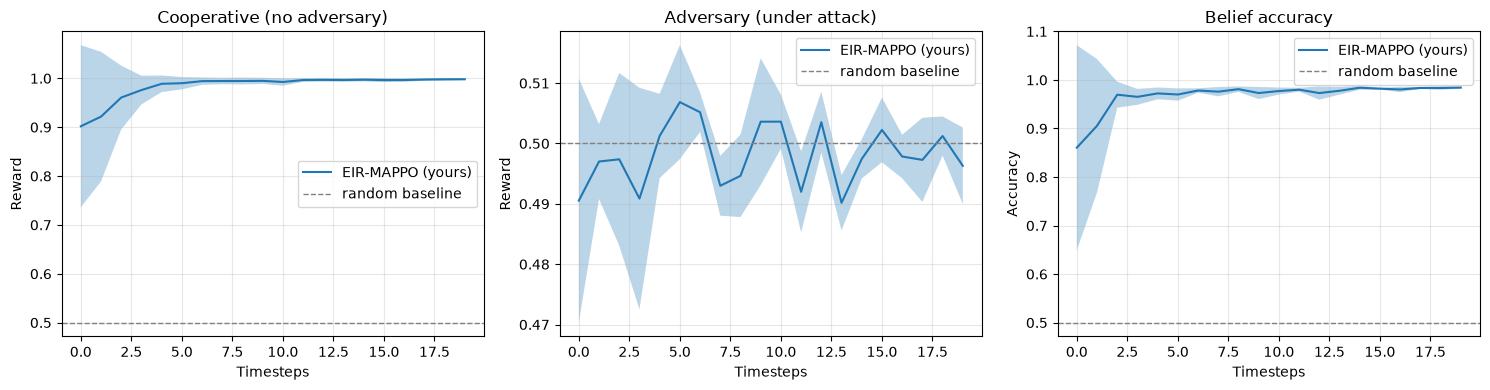

In [18]:
def plot_paper_style(all_hists):
    clean = np.array([h["reward_clean"] for h in all_hists])   # (n_seeds, n_points)
    adv   = np.array([h["reward_adv"]   for h in all_hists])
    acc   = np.array([h["belief_acc"]   for h in all_hists])
    def mean_ci(x):
        m = x.mean(axis=0)
        se = x.std(axis=0) / np.sqrt(x.shape[0])
        ci = 1.96 * se
        return m, ci
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, data, title in zip(axes, [clean, adv, acc],
                              ["Cooperative (no adversary)", "Adversary (under attack)",
                               "Belief accuracy"]):
        m, ci = mean_ci(data)
        x = np.arange(len(m))
        ax.plot(x, m, label="EIR-MAPPO (yours)")
        ax.fill_between(x, m - ci, m + ci, alpha=0.3)
        ax.set_xlabel("Timesteps")
        ax.set_ylabel("Reward" if "Belief" not in title else "Accuracy")
        ax.set_title(title)
        ax.axhline(0.5, color='gray', linestyle='--', linewidth=1, label='random baseline')
        ax.legend()
        ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
plot_paper_style(all_hists)

In [22]:
for state_idx in [0, 1]:
    s = np.zeros((1, game.n_states), dtype=np.float32); s[0, state_idx] = 1.0
    b = np.zeros((1, game.N+1), dtype=np.float32); b[0, 0] = 1.0   # "nobody" belief
    for agent_id in range(game.N):
        idv = np.zeros((1, game.N), dtype=np.float32); idv[0, agent_id] = 1.0
        logits = policy([s, idv, b]).numpy()
        probs = np.exp(logits) / np.exp(logits).sum()
        print(f"state s{state_idx+1}, agent {agent_id}: action probs = {probs.round(3)}")

state s1, agent 0: action probs = [[0.992 0.008]]
state s1, agent 1: action probs = [[1. 0.]]
state s2, agent 0: action probs = [[0. 1.]]
state s2, agent 1: action probs = [[1. 0.]]


In [29]:
# ============================================================
# Honest evaluation: freeze the trained team, train a FRESH
# adversary from scratch against it. Mirrors mappo_traitor_belief.
# ============================================================

def run_frozen_eval_episodes(game, atk_adversary, hidden=HIDDEN):
    """Same rollout as run_episodes, but policy/critic/belief are frozen
       (inference only) and the adversary is the fresh network being trained here."""
    game.reset()
    theta = game.sample_types()   # game.p_no_adv should be 0.0 -> always one adversary present

    prev_actions = np.zeros((game.B, game.N), dtype=int)
    h = tf.zeros((game.B, hidden))
    S_state, S_belief, S_actions, S_reward, S_feat, S_old_logp_adv = [], [], [], [], [], []

    for t in range(game.ep_len):
        obs_all = game._obs()
        state_oh = obs_all[:, 0, :]

        b_in = belief_input(state_oh, prev_actions, game)
        b_tf, h = belief_step(tf.constant(b_in), h)          # frozen belief
        b_t = b_tf.numpy()

        state_rep = obs_all.reshape(-1, game.n_states)
        id_rep = np.tile(np.eye(game.N, dtype=np.float32), (game.B, 1))
        belief_rep = np.repeat(b_t, game.N, axis=0)
        c_logits = policy([state_rep, id_rep, belief_rep]).numpy()   # frozen policy
        a_coop = choose_action(c_logits).reshape(game.B, game.N)

        a_logits = atk_adversary(state_rep).numpy()                  # FRESH adversary, training
        a_adv = choose_action(a_logits).reshape(game.B, game.N)
        logp_adv = tf.nn.log_softmax(a_logits, axis=-1)
        old_lp_adv = tf.reshape(
            tf.gather(logp_adv, a_adv.reshape(-1), batch_dims=1), (game.B, game.N)
        )

        actions = np.where(theta == 1, a_adv, a_coop)
        _, r, done = game.step(actions)

        S_state.append(state_oh); S_belief.append(b_t)
        S_actions.append(actions.copy()); S_reward.append(r); S_feat.append(b_in)
        S_old_logp_adv.append(old_lp_adv.numpy())
        prev_actions = actions
        if done: break

    stack = lambda L: np.stack(L, axis=1)
    return dict(
        state=stack(S_state), belief=stack(S_belief),
        actions=stack(S_actions), reward=stack(S_reward), feat=stack(S_feat),
        old_logp_adv=stack(S_old_logp_adv),
        theta=np.repeat(theta[:, None, :], len(S_reward), axis=1),
    )

@tf.function(reduce_retracing=True)
def _adversary_ppo_step_fresh(state_rep, actions_flat, old_logp, weight, mask, norm,
                              adversary, opt, clip, entropy_coef=0.01):
    with tf.GradientTape() as tape:
        logits = adversary(state_rep)
        logp = tf.nn.log_softmax(logits, axis=-1)
        probs = tf.nn.softmax(logits, axis=-1)
        entropy = -tf.reduce_sum(probs * logp, axis=-1)
        new_logp = tf.gather(logp, actions_flat, batch_dims=1)
        ratio = tf.exp(new_logp - old_logp)
        unclipped = ratio * weight
        clipped   = tf.clip_by_value(ratio, 1.0 - clip, 1.0 + clip) * weight
        adv_loss = tf.reduce_sum(tf.maximum(unclipped, clipped)) / norm
        entropy_bonus = tf.reduce_sum(entropy * mask) / norm
        loss = adv_loss - entropy_coef * entropy_bonus
    grads = tape.gradient(loss, adversary.trainable_variables)
    opt.apply_gradients(zip(grads, adversary.trainable_variables))
    return loss

def update_adversary_frozen(traj, adv, game, net, opt):
    """Same math as update_adversary, targeting a caller-supplied network/optimizer."""
    B, T = adv.shape
    state    = traj['state'].reshape(B*T, game.n_states)
    actions  = traj['actions'].reshape(B*T, game.N)
    theta    = traj['theta'].reshape(B*T, game.N).astype(np.float32)
    old_logp = traj['old_logp_adv'].reshape(B*T, game.N)
    adv_flat = adv.reshape(B*T)

    state_rep    = np.repeat(state, game.N, axis=0).astype(np.float32)
    actions_flat = actions.reshape(-1).astype(np.int32)
    old_logp_flat = old_logp.reshape(-1).astype(np.float32)
    weight = (theta * adv_flat[:, None]).reshape(-1).astype(np.float32)
    norm = np.float32(np.sum(theta) + 1e-8)

    loss = _adversary_ppo_step_fresh(tf.constant(state_rep), tf.constant(actions_flat),
                           tf.constant(old_logp_flat), tf.constant(weight),
                           tf.constant(theta.reshape(-1).astype(np.float32)), tf.constant(norm),
                           net, opt, game.ppo_clip)
    return float(loss)


def train_fresh_adversary(B=10, n_iters=2000, log_every=100, seed=123):
    """Freeze the trained team; train a brand-new adversary from scratch against it.
       This is the honest robustness number -- mirrors mappo_traitor_belief."""
    tf.random.set_seed(seed); np.random.seed(seed)

    fresh_adversary = build_adversary(game)             # random init, never seen this team
    opt_fresh_adv = tf.keras.optimizers.legacy.Adam(lr_adv)

    eval_game = ToyGame(B)
    eval_game.p_no_adv = 0.0                            # always attacked (matches adv_prob=1)

    hist = {"reward_adv": [], "belief_acc": []}
    t0 = time.time()

    for it in range(1, n_iters + 1):
        traj = run_frozen_eval_episodes(eval_game, fresh_adversary)
        G, adv = compute_gae(traj, eval_game)            # frozen critic, inference only

        for _ in range(eval_game.ppo_epochs):
            update_adversary_frozen(traj, adv, eval_game, fresh_adversary, opt_fresh_adv)

        if it % log_every == 0:
            ra = traj['reward'].mean(axis=1).mean()       # every episode is attacked now
            pred_label = traj['belief'].argmax(axis=2)
            true_label = theta_to_onehot(traj['theta'], eval_game).argmax(axis=2)
            acc = (pred_label == true_label).mean()

            hist["reward_adv"].append(ra); hist["belief_acc"].append(acc)
            print(f"iter {it:5d} | honest reward(adv) {ra:.3f} | belief acc {acc:.3f} | {time.time()-t0:.0f}s")

    return hist, fresh_adversary

honest_hist, fresh_adversary = train_fresh_adversary(B=100, n_iters=6000, log_every=100)

iter   100 | honest reward(adv) 0.499 | belief acc 0.980 | 23s
iter   200 | honest reward(adv) 0.507 | belief acc 0.980 | 45s
iter   300 | honest reward(adv) 0.496 | belief acc 0.971 | 67s
iter   400 | honest reward(adv) 0.488 | belief acc 0.984 | 89s
iter   500 | honest reward(adv) 0.496 | belief acc 0.978 | 112s
iter   600 | honest reward(adv) 0.487 | belief acc 0.976 | 134s
iter   700 | honest reward(adv) 0.490 | belief acc 0.980 | 156s
iter   800 | honest reward(adv) 0.492 | belief acc 0.978 | 178s
iter   900 | honest reward(adv) 0.497 | belief acc 0.980 | 200s
iter  1000 | honest reward(adv) 0.498 | belief acc 0.978 | 222s
iter  1100 | honest reward(adv) 0.486 | belief acc 0.981 | 244s
iter  1200 | honest reward(adv) 0.494 | belief acc 0.979 | 266s
iter  1300 | honest reward(adv) 0.491 | belief acc 0.979 | 289s
iter  1400 | honest reward(adv) 0.501 | belief acc 0.977 | 311s
iter  1500 | honest reward(adv) 0.487 | belief acc 0.979 | 333s
iter  1600 | honest reward(adv) 0.492 | beli

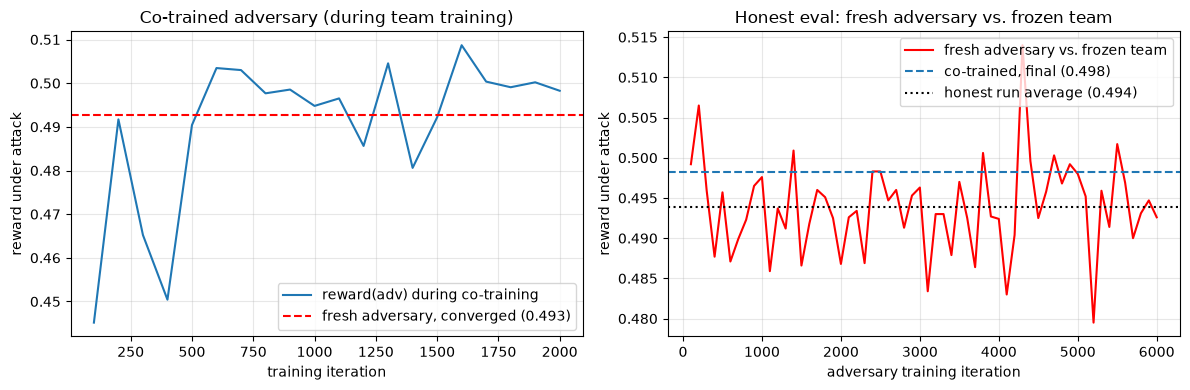

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# left: co-trained adversary over the original run
x_co = np.arange(1, len(all_hists[0]["reward_adv"]) + 1) * 100   # log_every=100 used in cell 16
axes[0].plot(x_co, all_hists[0]["reward_adv"], label="reward(adv) during co-training")
axes[0].axhline(honest_hist["reward_adv"][-1], color='red', linestyle='--',
                 label=f"fresh adversary, converged ({honest_hist['reward_adv'][-1]:.3f})")
axes[0].set_xlabel("training iteration"); axes[0].set_ylabel("reward under attack")
axes[0].set_title("Co-trained adversary (during team training)")
axes[0].legend(); axes[0].grid(alpha=0.3)

# right: the fresh adversary's own training curve, frozen team
x_honest = np.arange(1, len(honest_hist["reward_adv"]) + 1) * 100  # log_every=100 in train_fresh_adversary
axes[1].plot(x_honest, honest_hist["reward_adv"], color='red', label="fresh adversary vs. frozen team")
axes[1].axhline(all_hists[0]["reward_adv"][-1], color='C0', linestyle='--',
                 label=f"co-trained, final ({all_hists[0]['reward_adv'][-1]:.3f})")
axes[1].set_xlabel("adversary training iteration"); axes[1].set_ylabel("reward under attack")
axes[1].set_title("Honest eval: fresh adversary vs. frozen team")
avg_honest = np.mean(honest_hist["reward_adv"])
axes[1].axhline(avg_honest, color='black', linestyle=':', linewidth=1.5,
                 label=f"honest run average ({avg_honest:.3f})")
axes[1].legend()
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [32]:
partner_of = {0: 1, 1: 0}  # for N=2, each agent's partner is the other agent

scenarios = {
    "nobody corrupted":         lambda partner: np.eye(game.N + 1, dtype=np.float32)[0],
    "partner is the adversary": lambda partner: np.eye(game.N + 1, dtype=np.float32)[partner + 1],
}

for state_idx in [0, 1]:
    s = np.zeros((1, game.n_states), dtype=np.float32); s[0, state_idx] = 1.0
    for agent_id in range(game.N):
        idv = np.zeros((1, game.N), dtype=np.float32); idv[0, agent_id] = 1.0
        partner = partner_of[agent_id]
        for label, belief_fn in scenarios.items():
            b = belief_fn(partner).reshape(1, -1)
            logits = policy([s, idv, b]).numpy()
            probs = np.exp(logits) / np.exp(logits).sum()
            print(f"state s{state_idx+1}, agent {agent_id}, belief='{label}': action probs = {probs.round(3)}")
    print()

state s1, agent 0, belief='nobody corrupted': action probs = [[0.992 0.008]]
state s1, agent 0, belief='partner is the adversary': action probs = [[0.43 0.57]]
state s1, agent 1, belief='nobody corrupted': action probs = [[1. 0.]]
state s1, agent 1, belief='partner is the adversary': action probs = [[0.508 0.492]]

state s2, agent 0, belief='nobody corrupted': action probs = [[0. 1.]]
state s2, agent 0, belief='partner is the adversary': action probs = [[0.525 0.475]]
state s2, agent 1, belief='nobody corrupted': action probs = [[1. 0.]]
state s2, agent 1, belief='partner is the adversary': action probs = [[0.584 0.416]]

